For an EMCCD each pixel's temporal statistics follow
$$\langle S\rangle = b + M g\,N_e \qquad \sigma^2 = \sigma_r^2 + F^2 M^2 g^2\,N_e$$

* $b$ – bias offset (ADU), $\sigma_r^2$ – read-noise variance (ADU²)
* $N_e$ – mean photo-electrons per pixel per frame
* $M$ – EM gain, $g$ – base conversion gain (ADU/e⁻), $F^2$ – excess noise factor (≈ 2 for $M \gtrsim 10$)

So $\sigma^2$ vs $\langle S\rangle$ is a straight line of slope **$F^2 M g$**. Dividing by $F^2$ gives the
effective gain $Mg$ (ADU per input electron), and with a known base sensitivity $1/g$ the real EM gain $M$.


In [22]:
import os
import numpy as np
import pandas as pd
import tifffile
import json
from pathlib import Path
import matplotlib.pyplot as plt

def read_mm_metadata(tif):
    # Micro-Manager stores per-frame metadata as JSON in TIFF tag 51123
    tag = tif.pages[0].tags.get(51123)
    if tag is None:
        return {}
    return json.loads(tag.value) if isinstance(tag.value, str) else tag.value

def load_tiff_frame(path, index):
    """Load one frame (page) from a multi-page TIFF without reading the rest."""
    with tifffile.TiffFile(path) as tif:
        n = len(tif.pages)
        if not -n <= index < n:
            raise IndexError(f"Frame {index} out of range (file has {n} frames)")
        return tif.pages[index].asarray(),n

def get_file_list(dir,ending=".tif"):
    #dir = '/Volumes/Samsung_T3/Olivias/CMOS PTC/'
    file_list = []
    for file in os.listdir(dir):
        if file.endswith(ending):
            file_name = dir + '/' +file
            file_list.append(file_name)
    return file_list

def get_stack(filename,start=1):
    stack = []
    data, n = load_tiff_frame(filename,0)
    for I in range(start,n):
        data = load_tiff_frame(filename,I)
        stack.append(data[0])
    return np.asarray(stack)

def get_stack_stats(stack):
    mean_px = stack.mean(axis=0)
    var_px = stack.var(axis=0, ddof=1)
    diff_var_px = np.diff(stack, axis=0).var(axis=0) / 2
    return mean_px,var_px,diff_var_px

def get_file_info(filename):
    with tifffile.TiffFile(filename) as tif:
        meta = read_mm_metadata(tif)
    info = {
        "file": Path(filename).name,
        "exposure_ms": float(meta.get("Exposure-ms", np.nan)),
        "em_gain": int(meta.get("Andor-Gain", -1)),
        "preamp": meta.get("Andor-Pre-Amp-Gain"),
        "readout": meta.get("Andor-ReadoutMode"),
        "temp_C": meta.get("Andor-CCDTemperature"),
    }
    return info


In [33]:
position = 0
files = get_file_list("/Users/ashleycadby/PycharmProjects/EMCCD_Noise/PTC_80")
mean = []
noise = []
noise_FP = []
for position in range(len(files)):
    #print(get_file_info(files[position]))
    stack = get_stack(files[position])
    a,b,c = get_stack_stats(stack)
    mean.append(a)
    noise.append(b)
    noise_FP.append(c)

real_mean = np.asarray(mean)
real_noise = np.asarray(noise)
real_noise_FP = np.asarray(noise_FP)


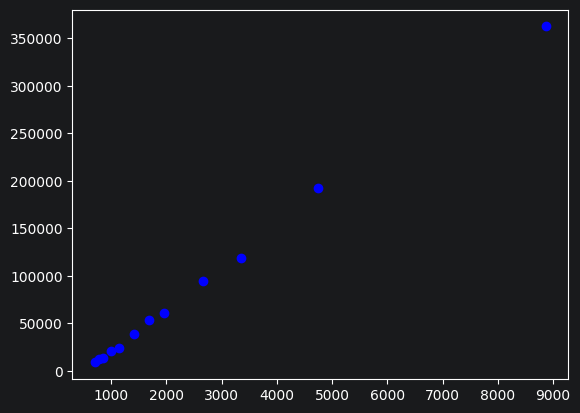

In [45]:
region_signal = np.mean(real_mean[:,500:510,500],axis=1)
region_noise = np.mean(real_noise[:, 500:510,500],axis=1)
plt.plot(region_signal,region_noise ,'bo')
#plt.loglog(real_mean[:,1,1],real_noise_FP[:,1,1],'ro')